# Часть 1. Разбор данных

Датасет: kaggle.com/datasets/preethi866/vegetable-dataset. Перед запуском нужно скачать данные (`python download_data.py`)
и задать путь в переменной `VEG_DATA` (или положить датасет в папку `data/`).

План:
1. сколько картинок, какие размеры, как получены (смотрю и на имена файлов)
2. дубликаты и почти-дубликаты
3. можно ли доверять готовому разбиению train/test
4. что может помешать на настоящих фото из магазина

In [1]:
import os, sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import imagehash
import torch

sys.path.append("..")
from common import CLASSES, get_data_dir, load_image, build_model, eval_tf

DATA = get_data_dir()
if not os.path.isabs(DATA):
    DATA = os.path.join("..", DATA)
FIG = "../reports/figures"
os.makedirs(FIG, exist_ok=True)
pd.set_option("display.width", 200)
print(os.listdir(DATA))

['Dataset', 'final_dataset']


## 1. Сколько картинок и как они получены

В архиве две папки: `Dataset/Dataset/<класс>` и `final_dataset/final_dataset/{train,val,test}/<класс>`.

In [2]:
sources = {
    "Dataset": "Dataset/Dataset",
    "train": "final_dataset/final_dataset/train",
    "val": "final_dataset/final_dataset/val",
    "test": "final_dataset/final_dataset/test",
}
rows = []
for src, sub in sources.items():
    for cls in CLASSES:
        folder = os.path.join(DATA, sub, cls)
        for name in sorted(os.listdir(folder)):
            rows.append({"src": src, "cls": cls, "name": name, "path": os.path.join(folder, name)})
files = pd.DataFrame(rows)
pd.crosstab(files["cls"], files["src"], margins=True)[["Dataset", "train", "val", "test", "All"]]

src,Dataset,train,val,test,All
cls,,,,,
Capsicum,615,590,117,117,1439
Carrot,905,876,174,177,2132
Cucumber,308,295,57,58,718
Potato,422,416,116,114,1068
Raddish,286,283,79,79,727
Squash,1343,1319,259,254,3175
All,3879,3779,802,799,9259


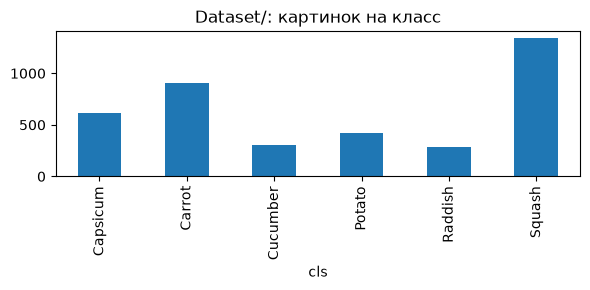

max/min = 4.7


In [3]:
ds = files[files["src"] == "Dataset"].reset_index(drop=True)
counts = ds["cls"].value_counts().reindex(CLASSES)
counts.plot.bar(figsize=(6, 3), title="Dataset/: картинок на класс")
plt.tight_layout(); plt.savefig(f"{FIG}/class_counts.png", dpi=100); plt.show()
print("max/min =", round(counts.max() / counts.min(), 1))

* В `final_dataset` в сумме 5380 картинок, а в `Dataset/` 3879, хотя это должен быть тот же датасет, только разбитый. Значит там есть повторы (проверяю в п.2).
* Дисбаланс классов: Squash 1343, Raddish 286, разница почти в 5 раз. Учту весами в loss и буду смотреть macro-F1, а не только accuracy.

In [4]:
# размеры, режим, exif (камера и поворот)
info = []
for p in ds["path"]:
    im = Image.open(p)
    exif = im.getexif()
    info.append((im.size[0], im.size[1], im.mode, os.path.getsize(p) // 1024, exif.get(272), exif.get(274)))
ds[["w", "h", "mode", "kb", "camera", "exif_orient"]] = pd.DataFrame(info)
ds["is_frame"] = ds["name"].str.contains("_frame_")
ds["size"] = ds["w"].astype(str) + "x" + ds["h"].astype(str)
ds.groupby(["is_frame", "size", "mode"]).agg(
    n=("name", "size"), median_kb=("kb", "median"),
    camera=("camera", lambda s: list(s.dropna().unique())),
    exif_orient=("exif_orient", lambda s: dict(s.value_counts())))

n  median_kb      camera                         exif_orient
is_frame size      mode                                                                 
False    3456x3456 RGB     77     3020.0  [SM-A536E]  {6.0: 55, 8.0: 18, 1.0: 3, 3.0: 1}
         4624x2084 RGB    108     2516.0  [SM-A536E]   {6.0: 99, 1.0: 7, 3.0: 1, 8.0: 1}
True     200x200   RGB   3694       16.0          []                                  {}

* Есть два типа картинок. **Кадры** (3694 шт, 95% датасета) все 200x200 и весят около 16 КБ, то есть это уже уменьшенные кадры из видео. **Фото** (185 шт) полноразмерные (3456x3456 и 4624x2084), камера в EXIF одна: Samsung SM-A536E.
* У большинства фото в EXIF записан поворот (6 = повернуть на 90°). Если открыть фото без `ImageOps.exif_transpose`, оно будет лежать боком. В `common.load_image` я это учёл. Для фото из магазина это тоже важно.

In [5]:
# имена файлов: 20251113_210729_frame_12.jpg = дата_время съёмки + номер кадра из видео
print(ds["name"].sample(8, random_state=1).tolist())
ds["stamp"] = ds["name"].str.replace(r"(_frame_\d+)?\.jpg$", "", regex=True)
ds["day"] = ds["stamp"].str[:8]
ds["video"] = np.where(ds["is_frame"], ds["stamp"], None)
by_day = ds.groupby(["cls", "day"]).agg(
    videos=("video", "nunique"), frames=("is_frame", "sum"), photos=("is_frame", lambda s: (~s).sum()))
by_day

['20260101_134905_frame_69.jpg', '20251113_210803_frame_135.jpg', '20251210_230822.jpg', '20260101_134905_frame_401.jpg', '20251117_134731_frame_156.jpg', '20260101_134905_frame_157.jpg', '20260101_132840.jpg', '20251113_210310_frame_21.jpg']


videos  frames  photos
cls      day                             
Capsicum 20251113       0       0       4
         20251117       1     164       7
         20260101       2     409      31
Carrot   20251113       3     251       6
         20260101       3     629      19
Cucumber 20251113       1     168       8
         20251117       0       0       4
         20260101       1     125       3
Potato   20251113       1      98       5
         20260101       1     278      41
Raddish  20251210       2     260      26
Squash   20251113       1     272       7
         20251117       1     183       7
         20260101       2     857      17

In [6]:
print("всего видео:", ds["video"].nunique(), " отдельных фото:", (~ds["is_frame"]).sum(),
      " дней съёмки:", ds["day"].nunique(), sorted(ds["day"].unique()))
print("кадров в одном видео: от", ds[ds.is_frame].groupby("video").size().min(),
      "до", ds[ds.is_frame].groupby("video").size().max())

всего видео: 19  отдельных фото: 185  дней съёмки: 4 ['20251113', '20251117', '20251210', '20260101']
кадров в одном видео: от 24 до 607


Имена файлов это дата и время съёмки на телефоне, а `_frame_N` это номер кадра из видео. Отсюда главный вывод:
* На самом деле в датасете **19 видео и 185 фото**, снятых за **4 дня**. Одно видео даёт от 24 до 607 очень похожих кадров.
* На класс получается всего 2-6 видео. У Raddish вообще один день съёмки.
* То есть 9300 картинок сильно завышают реальное разнообразие данных. Независимых "съёмок" мало.

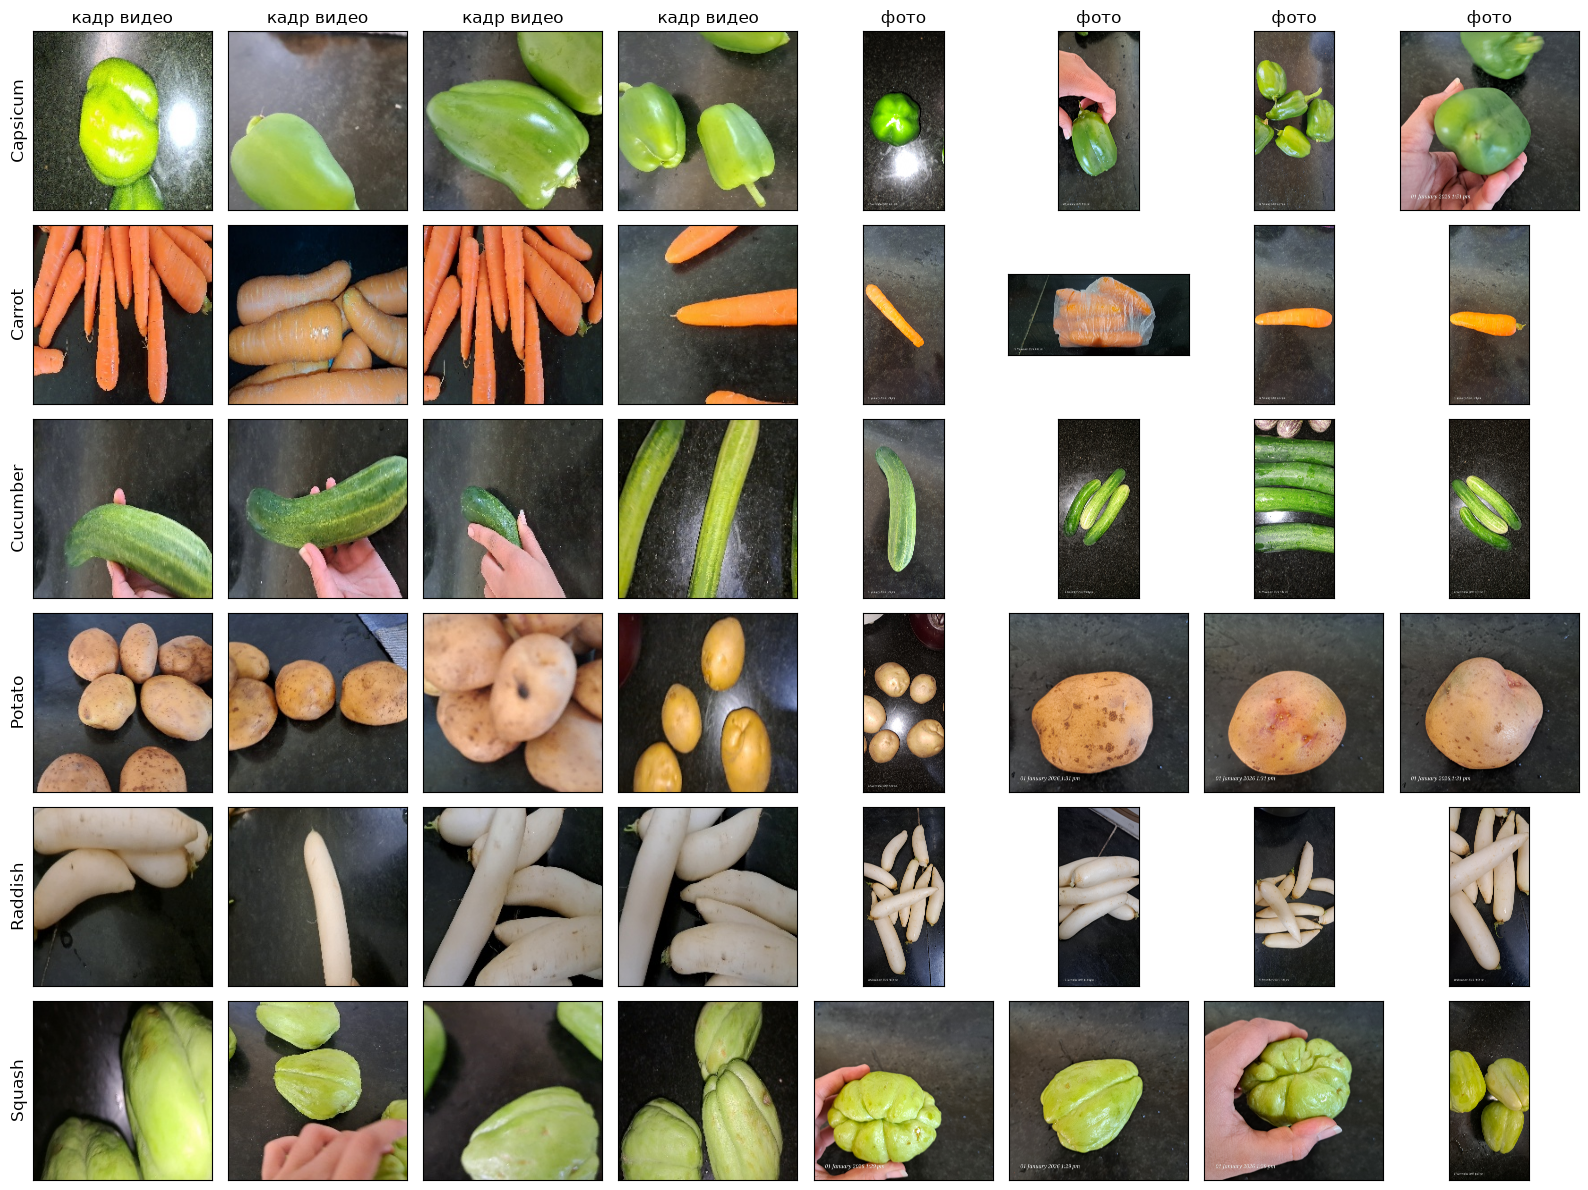

In [7]:
# как выглядят картинки: по 4 кадра из видео и 4 фото на класс
rng = np.random.RandomState(0)
fig, axes = plt.subplots(6, 8, figsize=(16, 12))
for r, cls in enumerate(CLASSES):
    g = ds[ds["cls"] == cls]
    pick = list(g[g.is_frame].sample(4, random_state=rng).path) + list(g[~g.is_frame].sample(4, random_state=rng).path)
    for k, p in enumerate(pick):
        ax = axes[r, k]
        ax.imshow(load_image(p)); ax.set_xticks([]); ax.set_yticks([])
        if k == 0: ax.set_ylabel(cls, fontsize=12)
        if r == 0: ax.set_title("кадр видео" if k < 4 else "фото")
plt.tight_layout(); plt.savefig(f"{FIG}/samples.png", dpi=70); plt.show()

* Всё снято на одной и той же тёмной столешнице (похоже на домашнюю кухню), часто овощ держат в руке. Магазина тут нет совсем.
* **Raddish** это белая редька (дайкон), а не красный редис. **Squash** это чайот, а не кабачок. **Capsicum** только зелёный перец.
* На фото внизу слева есть подпись с датой ("01 January 2026 1:31 pm"), на кадрах её нет.

## 2. Дубликаты

### 2.1 Точные дубликаты (md5 файла)

In [8]:
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

files["md5"] = [md5(p) for p in files["path"]]
ds["md5"] = files.loc[files.src == "Dataset", "md5"].values
print("уникальных файлов во всём архиве:", files["md5"].nunique(), "из", len(files))
print("дубликатов внутри Dataset/:", ds["md5"].duplicated().sum())
fin = files[files.src != "Dataset"]
print("файлов final_dataset, которых нет в Dataset/:", (~fin["md5"].isin(set(ds["md5"]))).sum())
train_md5 = set(files.loc[files.src == "train", "md5"])
for s in ["val", "test"]:
    part = files[files.src == s]
    print(f"{s}: {len(part)} картинок, из них точные копии файлов из train: {part['md5'].isin(train_md5).sum()}")
print("общих файлов val и test:", len(set(files.loc[files.src == "val", "md5"]) & set(files.loc[files.src == "test", "md5"])))

уникальных файлов во всём архиве: 3879 из 9259
дубликатов внутри Dataset/: 0
файлов final_dataset, которых нет в Dataset/: 0
val: 802 картинок, из них точные копии файлов из train: 727
test: 799 картинок, из них точные копии файлов из train: 717
общих файлов val и test: 108


In [9]:
# те картинки test, которые НЕ копии из train - из каких они видео?
ds_by_md5 = ds.set_index("md5")
t = files[(files.src == "test") & (~files["md5"].isin(train_md5))].copy()
t["video_or_day"] = ds_by_md5.loc[t["md5"], "stamp"].str[:15].values
train_stamps = set(ds_by_md5.loc[list(train_md5), "stamp"])
t["same_video_in_train"] = ds_by_md5.loc[t["md5"], "video"].isin(train_stamps).values
print("не-копий в test:", len(t), " из них кадры видео, другие кадры которого есть в train:", t["same_video_in_train"].sum())

не-копий в test: 82  из них кадры видео, другие кадры которого есть в train: 75


* В `final_dataset` нет ни одной новой картинки, все файлы скопированы из `Dataset/`.
* **717 из 799 картинок test (90%) это побайтно те же файлы, что лежат в train.** С val так же: 727 из 802. val и test ещё и пересекаются между собой (108 файлов).
* Из оставшихся 82 картинок test 75 это кадры из видео, соседние кадры которого лежат в train.

### 2.2 Почти-дубликаты

Два способа:
* perceptual hash (`imagehash.phash`, 64 бита) и расстояние Хэмминга между хешами. Ловит почти одинаковые картинки.
* эмбеддинги ResNet18 с imagenet (без последнего слоя) и косинусная близость. Ловит то, что phash пропускает (сдвиг, другой ракурс того же овоща).

Сравниваю все пары внутри `Dataset/` (там все уникальные картинки).

In [10]:
hashes = [imagehash.phash(load_image(p)) for p in ds["path"]]
H = np.array([int(str(h), 16) for h in hashes], dtype=np.uint64)
n = len(H)
D = np.zeros((n, n), dtype=np.uint8)
for i in range(n):
    D[i] = np.bitwise_count(H[i] ^ H)
np.fill_diagonal(D, 255)
ds["nn_hamming"] = D.min(1)
print(ds["nn_hamming"].describe())

count    3879.000000
mean        6.229956
std         5.004662
min         0.000000
25%         2.000000
50%         6.000000
75%        10.000000
max        20.000000
Name: nn_hamming, dtype: float64


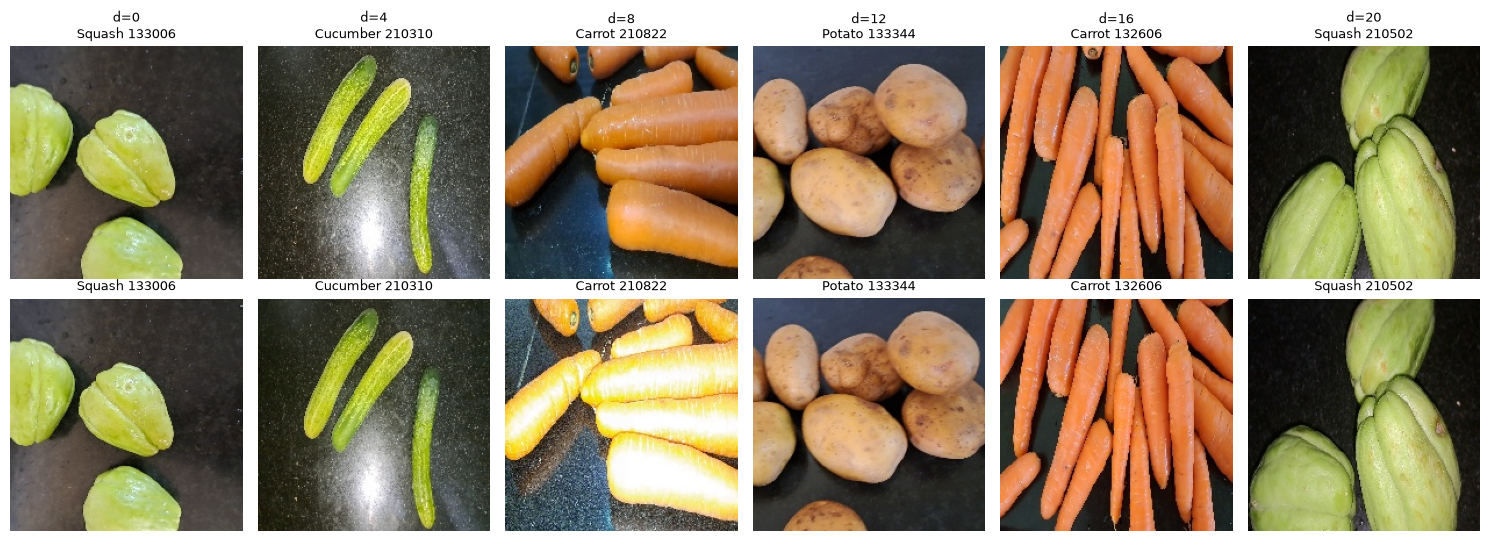

In [11]:
# какой порог считать почти-дубликатом: смотрю пары на разных расстояниях
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
for k, d in enumerate([0, 4, 8, 12, 16, 20]):
    ii, jj = np.where(np.triu(D == d, 1))
    if len(ii) == 0:
        axes[0, k].set_title(f"d={d}: нет пар"); continue
    m = np.random.RandomState(d).randint(len(ii))
    i, j = ii[m], jj[m]
    axes[0, k].imshow(load_image(ds.path[i])); axes[1, k].imshow(load_image(ds.path[j]))
    axes[0, k].set_title(f"d={d}\n{ds.cls[i]} {ds.stamp[i][9:]}", fontsize=9)
    axes[1, k].set_title(f"{ds.cls[j]} {ds.stamp[j][9:]}", fontsize=9)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/phash_pairs.png", dpi=70); plt.show()

В этих примерах даже при d=16-20 это всё ещё одна и та же сцена из одного видео (небольшой сдвиг или поменялась яркость). Получается, phash ловит почти-дубликаты только частично.
Порог беру `T=10`: до него почти все пары это одна и та же сцена, а ложные пары появляются как раз на границе (см. пары из разных классов ниже). Но основную группировку для разбиения делаю по видео и дню из имени файла, а не по phash.

In [12]:
T = 10  # порог, выбрал по картинкам выше
ii, jj = np.where(np.triu(D <= T, 1))
pairs = pd.DataFrame({"i": ii, "j": jj})
same_cls = ds.cls.values[ii] == ds.cls.values[jj]
same_day = ds.day.values[ii] == ds.day.values[jj]
same_video = (ds.video.values[ii] == ds.video.values[jj]) & ds.is_frame.values[ii]
pairs["kind"] = np.select(
    [same_video, same_cls & same_day, same_cls, ~same_cls],
    ["одно видео", "тот же класс и день, другое видео/фото", "тот же класс, другой день", "разные классы"], default="?")
print("пар с phash-расстоянием <=", T, ":", len(pairs))
print(pairs["kind"].value_counts())
print("картинок, у которых есть почти-дубликат:", (ds["nn_hamming"] <= T).sum(), "из", n)

пар с phash-расстоянием <= 10 : 12161
kind
одно видео                                12155
тот же класс и день, другое видео/фото        3
разные классы                                 3
Name: count, dtype: int64
картинок, у которых есть почти-дубликат: 3161 из 3879


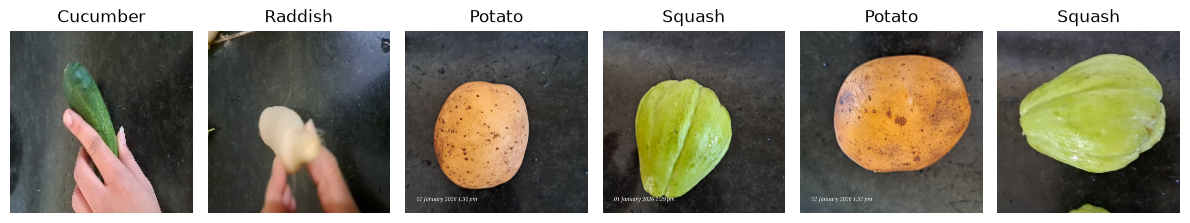

In [13]:
# пары из разных классов - что это?
cross = pairs[pairs.kind == "разные классы"]
fig, axes = plt.subplots(1, 2 * len(cross), figsize=(4 * len(cross), 3.5))
for k, (_, r) in enumerate(cross.iterrows()):
    for m, idx in enumerate([r.i, r.j]):
        axes[2 * k + m].imshow(load_image(ds.path[idx])); axes[2 * k + m].set_title(ds.cls[idx]); axes[2 * k + m].axis("off")
plt.tight_layout(); plt.show()

* 12155 из 12161 похожих пар это кадры одного видео. У 3161 из 3879 картинок есть почти-копия даже со строгим порогом.
* 3 пары из разных классов это ложные срабатывания phash: один овощ в центре на тёмном фоне, грубая "раскладка" картинки совпадает. Это ещё одна причина не строить группы только по phash.

In [14]:
# эмбеддинги замороженной ResNet18
device = "cuda" if torch.cuda.is_available() else "cpu"
model = build_model(pretrained=True)
model.fc = torch.nn.Identity()
model = model.to(device).eval()
emb = []
with torch.no_grad():
    for k in range(0, n, 64):
        x = torch.stack([eval_tf(load_image(p)) for p in ds.path[k:k + 64]]).to(device)
        emb.append(torch.nn.functional.normalize(model(x), dim=1).cpu())
E = torch.cat(emb).numpy()
S = E @ E.T
np.fill_diagonal(S, -1)
ds["nn_cos"] = S.max(1)
print(ds["nn_cos"].describe())

count    3879.000000
mean        0.979062
std         0.018651
min         0.817174
25%         0.976525
50%         0.984640
75%         0.989481
max         0.998783
Name: nn_cos, dtype: float64


По эмбеддингам та же картина: медиана близости к ближайшему соседу 0.985, почти у каждой картинки есть очень похожая.

## 3. Можно ли доверять готовому разбиению

Для каждой картинки из test смотрю самую похожую картинку из train (косинусная близость эмбеддингов).
Если test честный, похожих почти-копий быть не должно. Для сравнения то же самое для моего разбиения (`make_split.py`, кладёт `splits/split.csv`).

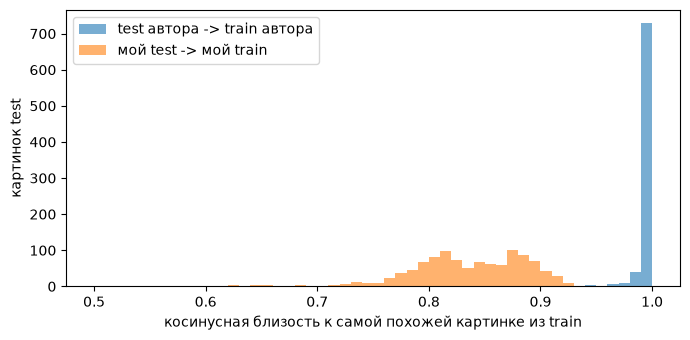

разбиение автора: доля test с близостью > 0.95: 98.6%, медиана 1.000
моё разбиение: доля test с близостью > 0.95: 0.0%, медиана 0.839
phash <= 10: автор 97.4% картинок test, у меня 0.0%


In [15]:
idx_by_md5 = pd.Series(ds.index.values, index=ds["md5"])

def nn_sim(test_idx, train_idx):
    return S[np.ix_(test_idx, train_idx)].max(1) if len(train_idx) else np.array([])

a_train = idx_by_md5[files.loc[files.src == "train", "md5"]].values
a_test = idx_by_md5[files.loc[files.src == "test", "md5"]].values
# у точной копии S = -1 на диагонали, поэтому отдельно помечаю копии как 1.0
a_sim = np.where(np.isin(a_test, a_train), 1.0, nn_sim(a_test, a_train))

split = pd.read_csv("../splits/split.csv")
ds_pos = pd.Series(ds.index.values, index=ds["cls"] + "/" + ds["name"])
split["i"] = ds_pos[split["cls"] + "/" + split["path"].str.split("/").str[-1]].values
m_train = split.loc[split.split == "train", "i"].values
m_test = split.loc[split.split == "test", "i"].values
m_sim = nn_sim(m_test, m_train)

plt.figure(figsize=(7, 3.5))
bins = np.linspace(0.5, 1.0, 51)
plt.hist(a_sim, bins=bins, alpha=0.6, label="test автора -> train автора")
plt.hist(m_sim, bins=bins, alpha=0.6, label="мой test -> мой train")
plt.xlabel("косинусная близость к самой похожей картинке из train"); plt.ylabel("картинок test")
plt.legend(); plt.tight_layout(); plt.savefig(f"{FIG}/nn_similarity.png", dpi=100); plt.show()

for name, sim in [("разбиение автора", a_sim), ("моё разбиение", m_sim)]:
    print(f"{name}: доля test с близостью > 0.95: {(sim > 0.95).mean():.1%}, медиана {np.median(sim):.3f}")

# то же самое по phash
a_ham = np.where(np.isin(a_test, a_train), 0, D[np.ix_(a_test, a_train)].min(1))
m_ham = D[np.ix_(m_test, m_train)].min(1)
print(f"phash <= {T}: автор {(a_ham <= T).mean():.1%} картинок test, у меня {(m_ham <= T).mean():.1%}")

In [16]:
pd.crosstab(split["cls"], split["split"], margins=True)[["train", "val", "test", "All"]]

split,train,val,test,All
cls,,,,
Capsicum,368,76,171,615
Carrot,512,136,257,905
Cucumber,130,50,128,308
Potato,269,50,103,422
Raddish,114,50,122,286
Squash,859,205,279,1343
All,2252,567,1060,3879


**Вывод: готовому разбиению доверять нельзя.** 90% test это копии файлов из train, а почти всё остальное это соседние кадры тех же видео.
Точность на таком test покажет, насколько хорошо модель запомнила эти 19 видео, а не как она будет работать на новых фото.
(Для сравнения я всё равно обучу модель и на разбиении автора, чтобы показать разницу в цифрах.)

**Как я разбил сам** (`make_split.py`):
* Делю не по картинкам, а по съёмкам. **test** = целый день съёмки для каждого класса. Модель не видит ни этот день, ни эти видео. День выбирал так, чтобы в нём было хотя бы одно видео и примерно 20-40% картинок класса.
* У Raddish всего один день, поэтому для него test = второе видео и фото, снятые после его начала (делю по времени). Для Raddish проверка получается слабее, чем для остальных классов.
* **val** берётся из оставшихся дней: куски видео по 50 кадров подряд и серии фото. Val из-за этого немного оптимистичный (соседние куски одного видео похожи), он нужен только чтобы выбрать эпоху.
* На гистограмме видно разницу: у моего test нет ни одной картинки с близостью > 0.95 к train (медиана 0.84), а у автора 98.6% test имеют почти-копию в train.

Минус такого разбиения: в test всего 17 групп (видео и серии фото), поэтому цифры на нём шумные. 1060 картинок в test это не 1060 независимых примеров.
Train тоже меньше, зато оценка честная.

## 4. Что может помешать на фото из магазина

1. **Фон и условия.** Всё снято на одной столешнице, дома, одним телефоном, за 4 дня. В магазине будут ящики, полки, сетки, пакеты, ценники и другой свет (лампы, холодный свет витрин).
2. **Масштаб и количество.** В данных овощ крупным планом, 1-10 штук. На фото полки овощей много и они мелкие, рядом другие товары. Классификатор, который смотрит на всю картинку целиком, может ошибаться.
3. **Сами классы.** Raddish = дайкон, Squash = чайот, Capsicum = только зелёный перец. Красный редис, кабачок, красный и жёлтый перец модель не видела. Кабачок, скорее всего, будет уходить в Cucumber.
4. **Нет класса "нет овоща / другой овощ".** Модель всегда выберет один из 6 классов, даже для пустой полки или яблок (бонус с unknown я не делал).
5. **Кадры vs фото.** 95% данных это кадры 200x200 из видео (смазанные, сжатые). Фото всего 185, а в магазине как раз будут фото.
6. **Мало независимых съёмок.** 19 видео, по сути одни и те же несколько овощей. Модель легко запомнит конкретную морковку, а не "морковь вообще".
7. **Лишние подсказки.** Руки в кадре, подпись с датой на фото. На них модель тоже может опираться.
8. **Дисбаланс** почти в 5 раз (Squash и Raddish).

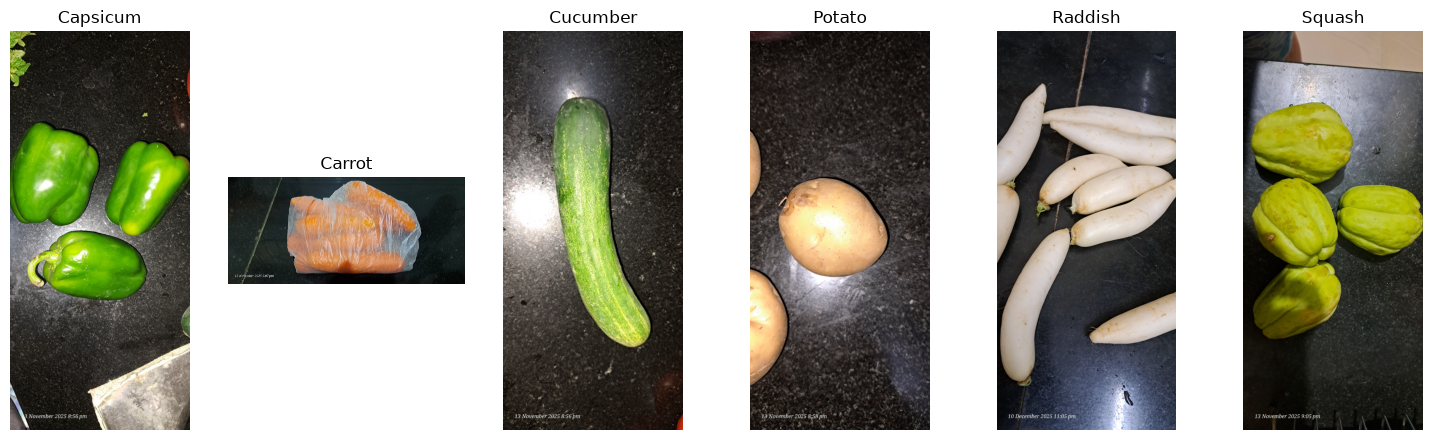

In [17]:
# примеры: фото с подписью даты, руки, как выглядят Raddish и Squash
ex = ds[~ds.is_frame].groupby("cls").head(1)
fig, axes = plt.subplots(1, 6, figsize=(15, 4.5))
for ax, (_, r) in zip(axes, ex.iterrows()):
    ax.imshow(load_image(r.path)); ax.set_title(r.cls); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/photos_examples.png", dpi=70); plt.show()